# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner
**Scenario.** A matatu association runs 14-seater vehicles on three routes out of Kampala. It wants to understand fares, forecast demand and decide how many vehicles to deploy.
Ntinda counts are from the original question; Entebbe and Mukono are **illustrative**.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.taxi import *

pd.set_option("display.float_format", "{:,.2f}".format)
routes = load_routes()
for r in routes.values(): print(r)

Route('Kampala-Ntinda', days=10, fare=UGX 2,000)
Route('Kampala-Entebbe', days=10, fare=UGX 5,000)
Route('Kampala-Mukono', days=10, fare=UGX 3,000)


## Task 1: the `Route` class: revenue and descriptive statistics

In [2]:
rows = []
for r in routes.values():
    d = r.describe()
    rows.append({"route": r.name, "fare (UGX)": r.fare, "mean pax/day": d["mean"], "variance": d["variance"], "std": d["std"],
                 "total revenue (UGX)": r.total_revenue(), "mean daily revenue (UGX)": r.daily_revenue().mean()})
display(pd.DataFrame(rows).set_index("route"))

,fare (UGX),mean pax/day,variance,std,total revenue (UGX),mean daily revenue (UGX)
route,,,,,,
Kampala-Ntinda,"2,000.00",47.40,54.27,7.37,"948,000.00","94,800.00"
Kampala-Entebbe,"5,000.00",67.80,45.07,6.71,"3,390,000.00","339,000.00"
Kampala-Mukono,"3,000.00",52.00,26.44,5.14,"1,560,000.00","156,000.00"


## Task 2: supply-demand equilibrium for Ntinda
`Qd = 120 - 0.02 P` and `Qs = 10 + 0.03 P`. Setting both equal to Q gives a 2x2 linear system in the unknowns (Q, P):

    Q + 0.02 P = 120
    Q - 0.03 P =  10

solved with `scipy.linalg.solve`.

Equilibrium: P* = UGX 2,200, Q* = 76 passengers per trip-hour
At the current fare UGX 2,000: demand = 80, supply = 70, excess demand = 10 passengers per trip-hour
Hand check: P* = (120-10)/(0.02+0.03) = 2200.0 ; Q* = 120 - 0.02*2200 = 76.0


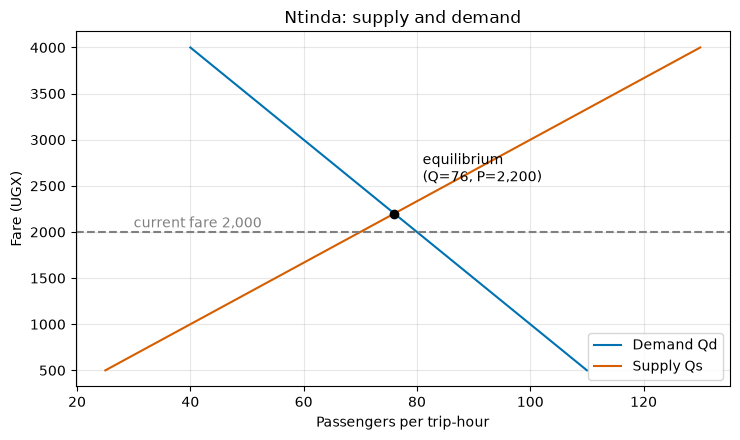

In [3]:
sd = SupplyDemand(a=120, b=0.02, c=10, d=0.03)
q_star, p_star = sd.equilibrium()
print(f"Equilibrium: P* = UGX {p_star:,.0f}, Q* = {q_star:.0f} passengers per trip-hour")
P_now = routes["Kampala-Ntinda"].fare
print(f"At the current fare UGX {P_now:,.0f}: demand = {sd.demand(P_now):.0f}, supply = {sd.supply(P_now):.0f}, "
      f"excess demand = {sd.excess_demand(P_now):.0f} passengers per trip-hour")
print("Hand check: P* = (120-10)/(0.02+0.03) =", (120 - 10) / 0.05, "; Q* = 120 - 0.02*2200 =", 120 - 0.02 * 2200)

P = np.linspace(500, 4000, 100)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot([sd.demand(p) for p in P], P, label="Demand Qd", color="#0072B2")
ax.plot([sd.supply(p) for p in P], P, label="Supply Qs", color="#D55E00")
ax.plot(q_star, p_star, "ko"); ax.annotate(f"equilibrium\n(Q={q_star:.0f}, P={p_star:,.0f})", (q_star, p_star), (q_star + 5, p_star + 350))
ax.axhline(P_now, ls="--", color="grey"); ax.text(30, P_now + 50, f"current fare {P_now:,.0f}", color="grey")
ax.set_xlabel("Passengers per trip-hour"); ax.set_ylabel("Fare (UGX)"); ax.set_title("Ntinda: supply and demand")
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout(); fig.savefig("../figures/p5_supply_demand.png", dpi=150); plt.show()

**Interpretation.** The equilibrium fare is **UGX 2,200** with 76 passengers per trip-hour. The current fare of UGX 2,000 is **below** equilibrium (by 200, or 9 %). At that price 80 passengers want a seat but operators supply only 70 seats, so there is **excess demand (a shortage) of 10 passengers per trip-hour**: queues, overloading, or passengers turned away. Raising the fare towards 2,200 would reduce demand and attract more supply until the market clears (though a regulated or association-set fare may deliberately sit below equilibrium).

## Task 3-4: forecasters and walk-forward backtest
Three `Forecaster` subclasses: `MovingAverage(3)`, `ExponentialSmoothing(alpha)` and `LinearTrend`. **Rolling origin:** for each target day 4 ... 10, fit on all earlier days and predict that day (7 one-step forecasts; no future data is ever used). MAE is in passengers. alpha is tuned per route by grid search (0.05 ... 1.00).

In [4]:
bt, alpha_best, alpha_scores = {}, {}, {}
for name, r in routes.items():
    y = r.passengers
    a, sc = grid_search_alpha(y, first_target_day=4)
    alpha_best[name], alpha_scores[name] = a, sc
    bt[name] = {
        "3-day moving average": rolling_mae(lambda: MovingAverage(3), y),
        f"SES (tuned alpha={a:.2f})": sc[a],
        "Linear trend": rolling_mae(lambda: LinearTrend(), y)}
mae_df = pd.DataFrame(bt)
display(mae_df.T)
print("Best alpha per route:", alpha_best)

,3-day moving average,SES (tuned alpha=1.00),Linear trend
Kampala-Ntinda,7.52,5.86,7.87
Kampala-Entebbe,7.19,4.43,7.71
Kampala-Mukono,5.33,3.71,6.39


Best alpha per route: {'Kampala-Ntinda': 1.0, 'Kampala-Entebbe': 1.0, 'Kampala-Mukono': 1.0}


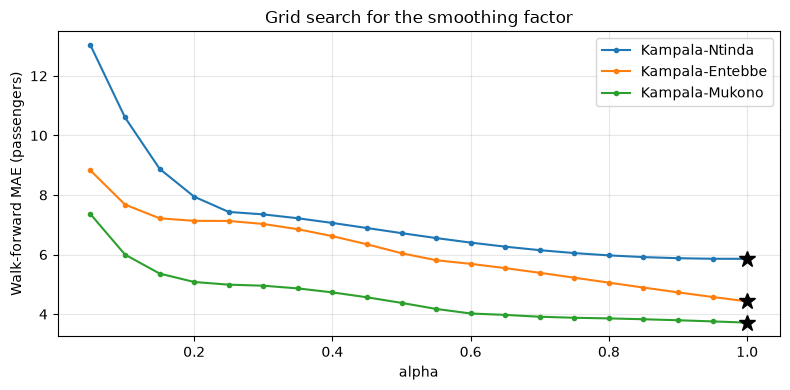

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, sc in alpha_scores.items():
    ax.plot(list(sc), list(sc.values()), marker="o", ms=3, label=name)
    ax.plot(alpha_best[name], sc[alpha_best[name]], "k*", ms=12)
ax.set_xlabel("alpha"); ax.set_ylabel("Walk-forward MAE (passengers)"); ax.set_title("Grid search for the smoothing factor")
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

The MAE keeps falling as alpha rises and is lowest at **alpha = 1.0** on all three routes, where SES simply repeats yesterday's value. Over days 4-10 the series rises to a peak on day 6 and then falls, so the most recent observation is the best guide. With only 7 test points, this is a weak, optimistic basis for choosing alpha (alpha is tuned and scored on the same days), and alpha = 1 is a boundary result, not a smoothing sweet spot.

## Task 5: forecast day 11 revenue with the best model

,best model,backtest MAE (pax),backtest MAE (UGX),day-11 pax,day-11 revenue (UGX)
route,,,,,
Kampala-Ntinda,SES (tuned alpha=1.00),5.86,"11,714.29",45.00,"90,000.00"
Kampala-Entebbe,SES (tuned alpha=1.00),4.43,"22,142.86",64.00,"320,000.00"
Kampala-Mukono,SES (tuned alpha=1.00),3.71,"11,142.86",50.00,"150,000.00"


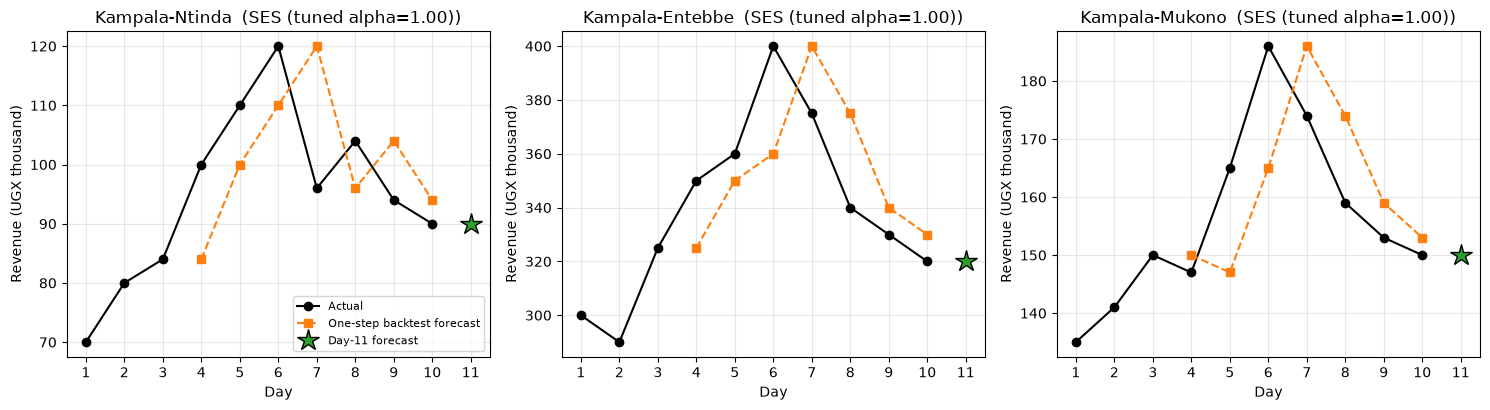

In [6]:
makers = {"3-day moving average": lambda: MovingAverage(3), "Linear trend": lambda: LinearTrend()}
rows, forecasts, backtests = [], {}, {}
for name, r in routes.items():
    y = r.passengers
    a = alpha_best[name]
    makers_r = dict(makers); makers_r[f"SES (tuned alpha={a:.2f})"] = lambda a=a: ExponentialSmoothing(a)
    best_name = mae_df[name].idxmin()
    model = makers_r[best_name]().fit(y)
    pax = float(model.predict(1)[0])
    forecasts[name] = (best_name, pax, pax * r.fare)
    backtests[name] = rolling_origin_forecasts(makers_r[best_name], y, 4)
    rows.append({"route": name, "best model": best_name, "backtest MAE (pax)": mae_df.loc[best_name, name],
                 "backtest MAE (UGX)": mae_df.loc[best_name, name] * r.fare, "day-11 pax": pax, "day-11 revenue (UGX)": pax * r.fare})
display(pd.DataFrame(rows).set_index("route"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, r) in zip(axes, routes.items()):
    rev = r.daily_revenue() / 1000
    days = np.arange(1, 11)
    ax.plot(days, rev, "ko-", label="Actual")
    actual_bt, fc_bt = backtests[name]
    ax.plot(np.arange(4, 11), fc_bt * r.fare / 1000, "s--", color="tab:orange", label="One-step backtest forecast")
    ax.plot(11, forecasts[name][2] / 1000, "*", ms=16, color="tab:green", mec="k", label="Day-11 forecast")
    ax.set_title(f"{name}  ({forecasts[name][0]})"); ax.set_xlabel("Day"); ax.set_ylabel("Revenue (UGX thousand)")
    ax.set_xticks(range(1, 12)); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8); fig.tight_layout(); fig.savefig("../figures/p5_forecast_revenue.png", dpi=150); plt.show()

## Task 6: fleet planning for day 11
One vehicle makes 8 one-way trips a day with 14 passengers, so it can carry **8 x 14 = 112 passengers a day**. Vehicles = ceil(forecast passengers x 1.15 / 112); we round **up** because a fraction of a vehicle cannot be deployed, and keep at least one vehicle where there is any demand.

In [7]:
rows = []
for name, r in routes.items():
    pax = forecasts[name][1]
    raw = pax * 1.15 / 112
    rows.append({"route": name, "forecast pax": pax, "with 15% buffer": pax * 1.15, "vehicle-equivalents": raw,
                 "vehicles to deploy": vehicles_needed(pax, trips_per_day=8, seats=14, buffer=0.15),
                 "utilisation of 1 vehicle (no buffer)": f"{100 * pax / 112:.0f}%"})
display(pd.DataFrame(rows).set_index("route"))

,forecast pax,with 15% buffer,vehicle-equivalents,vehicles to deploy,utilisation of 1 vehicle (no buffer)
route,,,,,
Kampala-Ntinda,45.00,51.75,0.46,1,40%
Kampala-Entebbe,64.00,73.60,0.66,1,57%
Kampala-Mukono,50.00,57.50,0.51,1,45%


Taken literally (counts are *total daily passengers on the route*), every route needs just **one** vehicle, running at 40-57 % of its 112-seat daily capacity. If the counts are actually per stage or per trip-hour (the Task 2 units), the plan would be very different, so this assumption should be confirmed with the association.

## Extension: 60 days with a weekly pattern; does seasonal naive beat the moving average?
`simulate_weekly_demand` generates 60 days (day 1 = Monday) with a Friday peak (+30 %), a quiet Sunday (-30 %) and seeded noise. Walk-forward evaluation starts on day 15, after two full weeks of history.

,walk-forward MAE (passengers)
Seasonal naive (7),4.35
Linear trend,6.83
SES (alpha=0.5),8.05
3-day moving average,8.25


Seasonal naive reduces MAE by 47% relative to the 3-day moving average


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
3-day moving average,4.29,3.43,4.33,5.52,16.83,4.83,21.06
Seasonal naive (7),7.71,3.14,2.29,2.14,4.33,4.17,7.00


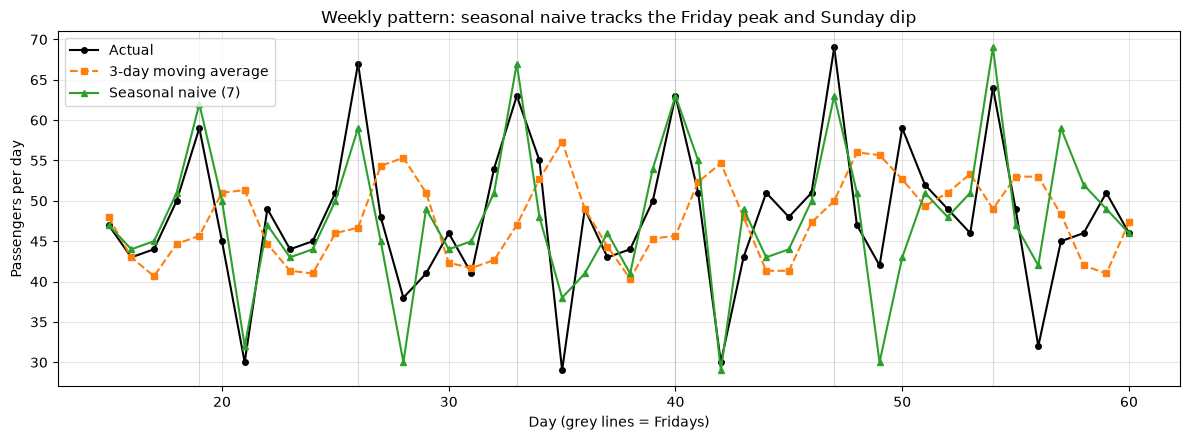

In [8]:
y60 = simulate_weekly_demand(days=60, base=46, noise_sd=4, seed=2026)
cands = {"3-day moving average": lambda: MovingAverage(3), "SES (alpha=0.5)": lambda: ExponentialSmoothing(0.5),
         "Linear trend": lambda: LinearTrend(), "Seasonal naive (7)": lambda: SeasonalNaive(7)}
res = {n: rolling_mae(f, y60, first_target_day=15) for n, f in cands.items()}
ext = pd.Series(res, name="walk-forward MAE (passengers)").sort_values()
display(ext.to_frame())
imp = 100 * (1 - res["Seasonal naive (7)"] / res["3-day moving average"])
print(f"Seasonal naive reduces MAE by {imp:.0f}% relative to the 3-day moving average")
assert res["Seasonal naive (7)"] < res["3-day moving average"]

# error by weekday
wd = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
rows = {}
for n in ("3-day moving average", "Seasonal naive (7)"):
    a, f = rolling_origin_forecasts(cands[n], y60, 15)
    days = np.arange(15, 61)
    rows[n] = [np.mean(np.abs(a - f)[(days - 1) % 7 == k]) for k in range(7)]
display(pd.DataFrame(rows, index=wd).T)

a_ma, f_ma = rolling_origin_forecasts(cands["3-day moving average"], y60, 15)
a_sn, f_sn = rolling_origin_forecasts(cands["Seasonal naive (7)"], y60, 15)
fig, ax = plt.subplots(figsize=(12, 4.5))
d = np.arange(15, 61)
ax.plot(d, a_ma, "ko-", ms=4, label="Actual")
ax.plot(d, f_ma, "s--", ms=4, color="tab:orange", label="3-day moving average")
ax.plot(d, f_sn, "^-", ms=4, color="tab:green", label="Seasonal naive (7)")
for k in range(19, 61, 7): ax.axvline(k, color="grey", alpha=0.3, lw=0.8)
ax.set_xlabel("Day (grey lines = Fridays)"); ax.set_ylabel("Passengers per day")
ax.set_title("Weekly pattern: seasonal naive tracks the Friday peak and Sunday dip"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("../figures/p5_seasonal.png", dpi=150); plt.show()

## Findings & Limitations
**Findings.** Entebbe earns the most (UGX 3.39 m over 10 days, thanks to the UGX 5,000 fare) and Ntinda the least (0.95 m). For Ntinda, solving the 2x2 system gives an equilibrium fare of UGX 2,200 and 76 passengers per trip-hour; the current UGX 2,000 fare is 9 % below it, leaving a shortage of 10 passengers per trip-hour. In walk-forward testing over days 4-10, SES tuned to alpha = 1 (i.e. repeating yesterday's value) beat both the 3-day moving average and the linear trend on every route (MAE 3.7-5.9 passengers against 5.3-7.5 and 6.4-7.9). That result is fragile: it rests on 7 test points, alpha is tuned and scored on the same days, and it reflects a series that happened to rise to a mid-window peak, so the day-11 forecasts simply echo day 10 (45, 64 and 50 passengers, worth UGX 90,000, 320,000 and 150,000). Each route then needs one vehicle at 40-57 % utilisation. In the 60-day experiment a seasonal-naive forecaster cut the error by almost half relative to the moving average (MAE 4.4 vs 8.3), mainly because the moving average lags on Fridays and Sundays.

**Limitations.** Ten days cannot reveal a weekly cycle, so the real data cannot tell us which model is better in general; the 60-day series is synthetic and built to contain the pattern the seasonal model exploits. Linear and SES forecasts are single numbers with no prediction interval. The fleet calculation assumes counts are total route passengers, ignores peak-hour concentration and breakdowns, and the supply-demand equations are given, not estimated. Fares for Entebbe and Mukono and their counts are illustrative.